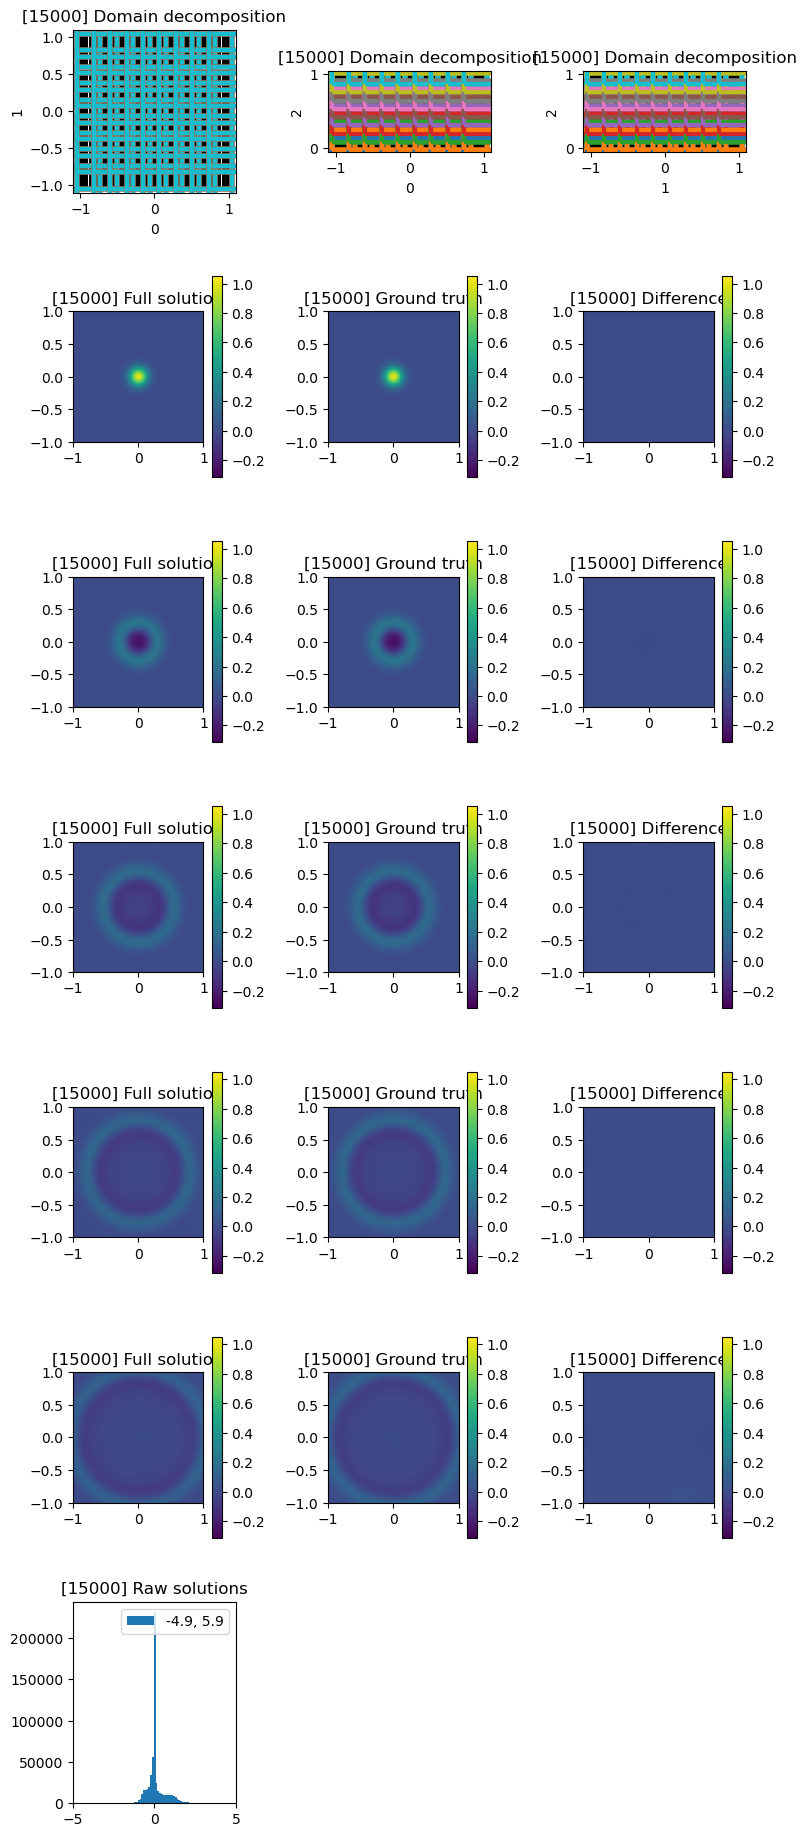

[INFO] 2023-08-05 17:52:27 - [i: 15000/15000] Training complete


In [3]:
import numpy as np

from fbpinns.domains import RectangularDomainND
from fbpinns.problems import WaveEquationConstantVelocity3D
from fbpinns.decompositions import RectangularDecompositionND
from fbpinns.networks import FCN
from fbpinns.constants import Constants, get_subdomain_ws
from fbpinns.trainers import FBPINNTrainer, PINNTrainer


subdomain_xs = [np.linspace(-1,1,10), np.linspace(-1,1,10), np.linspace(0,1,10)]
subdomain_ws = get_subdomain_ws(subdomain_xs, 2.4)

c = Constants(
    run="FBPINN solution",
    domain=RectangularDomainND,
    domain_init_kwargs=dict(
        xmin=np.array([-1,-1,0]),
        xmax=np.array([1,1,1]),
    ),
    problem=WaveEquationConstantVelocity3D,
    problem_init_kwargs=dict(
        c0=1,
        source=np.array([[0., 0., 0.1, 1.]]),# gaussian source x,y, width, amplitude
    ),
    decomposition=RectangularDecompositionND,
    decomposition_init_kwargs=dict(
        subdomain_xs=subdomain_xs,
        subdomain_ws=subdomain_ws,
        unnorm=(0.,0.1),
    ),
    network=FCN,
    network_init_kwargs=dict(
        layer_sizes=[3,8,1],
    ),
    ns=((50,50,50),),
    n_test=(100,100,5),
    n_steps=15000,
    clear_output=True,
)

run = FBPINNTrainer(c)
_ = run.train()

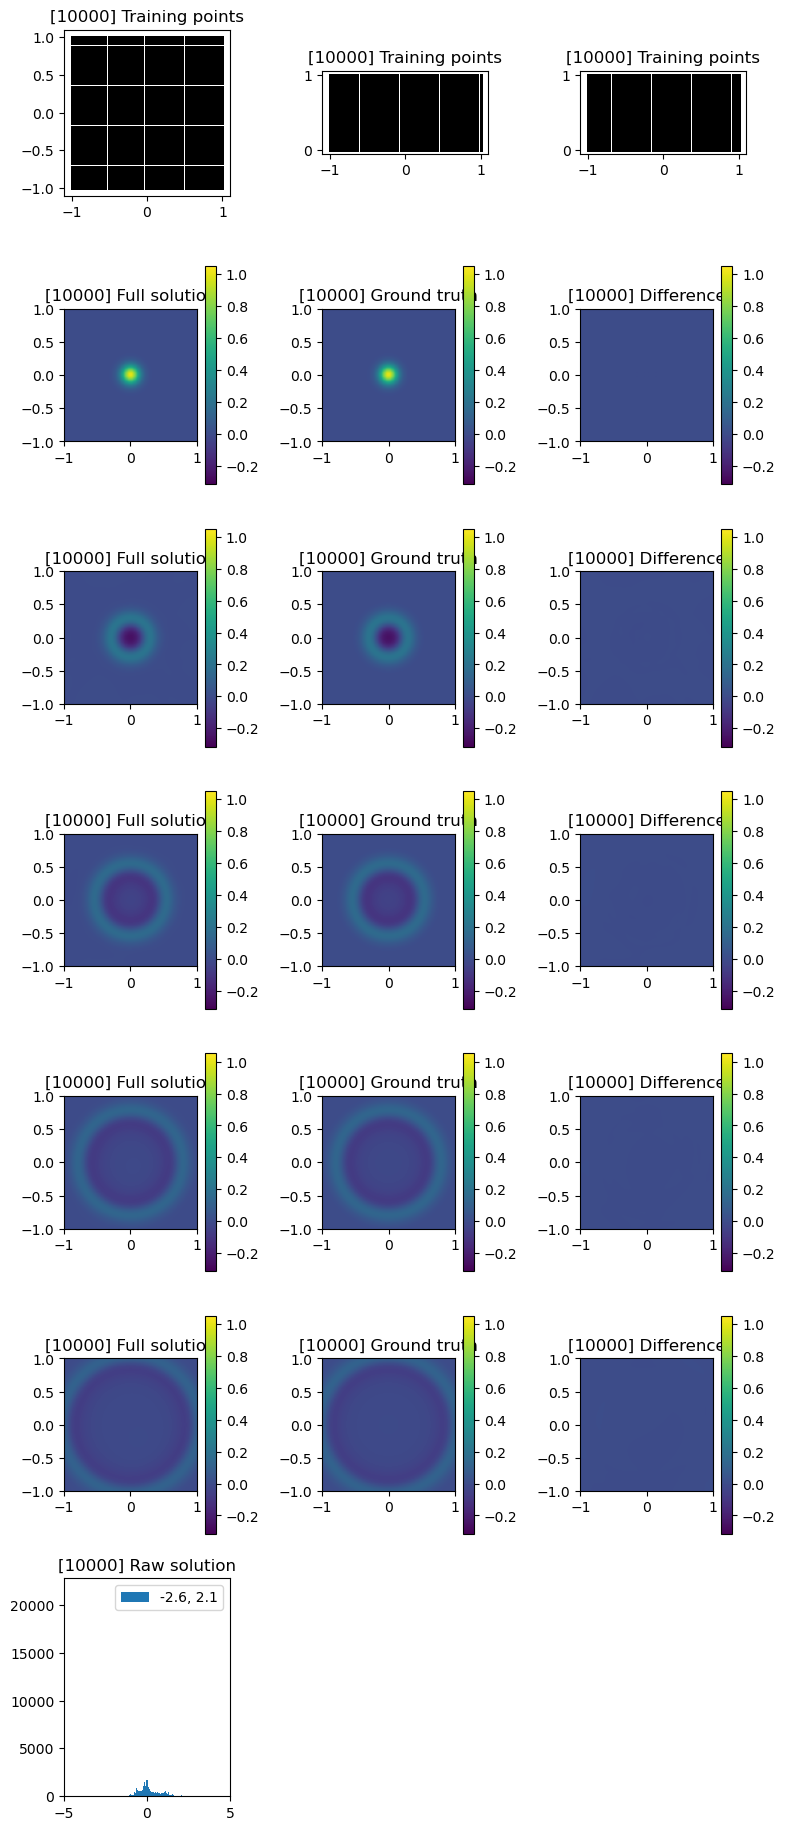

[INFO] 2023-08-05 23:16:23 - [i: 11000/15000] loss: 0.0293 rate: 0.6 elapsed: 4.81 hr PINN solution


KeyboardInterrupt: 

In [4]:
c["run"] = "PINN solution"
c["network_init_kwargs"] = dict(layer_sizes=[3,64,64,64,1])# use a larger neural network
run = PINNTrainer(c)
_ = run.train()# start training a PINN on the same problem

In [ ]:
import matplotlib.pyplot as plt
from fbpinns.analysis import load_model

plt.figure(figsize=0.7*np.array([6,4]))

c, model = load_model(run="FBPINN solution", rootdir="results/")
i, all_params, all_opt_states, active, u_test_losses = model

plt.plot(u_test_losses[:,2], u_test_losses[:,-2], label=c.run, color="tab:blue", linewidth=4, alpha=0.8)# flops

c, model = load_model(run="PINN solution", rootdir="results/")
i, all_params, all_opt_states, u_test_losses = model

plt.plot(u_test_losses[:,2], u_test_losses[:,-2], label=c.run, color="tab:red", linewidth=4, alpha=0.8)# flops

plt.yscale("log")
plt.legend()
plt.xlabel("FLOPs spent training", fontsize="large")
plt.ylabel("L1 test error", fontsize="large")

plt.show()